# Modeling Experiments

We perform some modeling experiments using various models. In the modeling experiment process, we only use the training set that we had obtained from earlier to do our work. 
We avoid peaking on the test set in [data/cleaned_data/test.csv](data/cleaned_data/test.csv). We perform analysis of the most relevant features as we proceed in the modeling experiments and continue with exploratory data analysis.

Our original base line model in [models/modeling_baselines.ipynb](models/modeling_baselines.ipynb) utilized the training and test split there. Here we take that training set and had it split into a new training set and a new validation set since we not want to peak at our final evaluation metric. The baseline model we had originally was a Logistic Regression model. It had limited feature engineering and did not utilize any informed imputation methods.

In [1]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, log_loss, 
                             classification_report, average_precision_score, precision_recall_curve)

from preprocessing import import_data
from scoring import score
import matplotlib.pyplot as plt


import warnings
warnings.filterwarnings("ignore")

# Feature Engineering Function

This section has a function designed to add features to the data set. These features are informed by EDA and domain specific knowledge regarding diabetes.

In [2]:
def add_features(df):
    # add features for dataframe here
    return df

# Train/Validation Split and Import Data

In [3]:
def train_val_split_data(x=False):

    if x==True:
        # Import the cleaned_data

        train = pd.read_csv("../data/cleaned_data/train.csv")
        X = train.drop(columns="target")
        y = train["target"]

        # The target is imbalanced. We also want to keep repeat patients together.

        # 1. Set n_splits=5 so the test size naturally becomes 1/5 = 20%
        sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

        # 2. Get the indices for the very first split next() gets only the first split for us
        train_idx, test_idx = next(sgkf.split(X, y, groups=X['patient_nbr']))

        # 3. Create a single train/test split
        Xt, Xv = X.iloc[train_idx], X.iloc[test_idx]
        yt, yv = y.iloc[train_idx], y.iloc[test_idx]


        # We will save the train / validation split here and use it for the modeling experiments

        train = Xt.copy()
        train["target"] = yt
        train.to_csv("modeling_data/train.csv",index=False)

        validation = Xv.copy()
        validation["target"] = yv 
        validation.to_csv("modeling_data/validation.csv",index=False)
    else:
        return
    
train_val_split_data(x=False)


# XGBoost Classifier

For helpful information regarding XGBoost Classifier, see https://xgboosting.com/

In [4]:
import xgboost as xgb
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [5]:
# Define XGBClassifier model parameters

spw = (yt == 0).sum() / (yt == 1).sum()   

params = {
    'objective': 'binary:logistic',
    'max_depth': 6,
    'learning_rate': 0.05,
    'n_estimators': 1_000,
    'subsample': 0.1,
    'enable_categorical': True,
    'colsample_bytree': 0.1,
    'scale_pos_weight': spw, # this deals with the class inbalance issue
    'random_state': 42,
}

num_cols = Xt.select_dtypes(include=["number", "bool"]).columns
cat_cols = [c for c in Xt.columns if c not in num_cols]

# Drop columns that are constant in training (decided from training only)
const_cols = [c for c in cat_cols if Xt[c].nunique(dropna=False) <= 1]
Xt = Xt.drop(columns=const_cols)
Xv = Xv.drop(columns=const_cols)
cat_cols = [c for c in cat_cols if c not in const_cols]

# Categories come from the training set; unseen levels in Xv become NaN
Xt = Xt.copy()
Xv = Xv.copy()
for c in cat_cols:
    dtype = pd.CategoricalDtype(categories=Xt[c].dropna().unique())
    Xt[c] = Xt[c].astype(dtype)
    Xv[c] = Xv[c].astype(dtype)

# Instantiate XGBClassifier with the parameters
model = xgb.XGBClassifier(**params)

# Train the model
model.fit(Xt, yt)

# Make predicted probabilities on the test set
probs = model.predict_proba(Xv)[:,1]

In [6]:
score(yv,y_pred=None,proba=probs,threshold=0.65)

Accuracy: 0.808
Confusion matrix:
 [[12676  1790]
 [ 1329   488]]
              precision    recall  f1-score   support

           0       0.91      0.88      0.89     14466
           1       0.21      0.27      0.24      1817

    accuracy                           0.81     16283
   macro avg       0.56      0.57      0.56     16283
weighted avg       0.83      0.81      0.82     16283

F1 @0.5: 0.238
ROC-AUC: 0.6349
PR-AUC:  0.1938
Best-threshold F1: 0.25725 at threshold 0.55464.


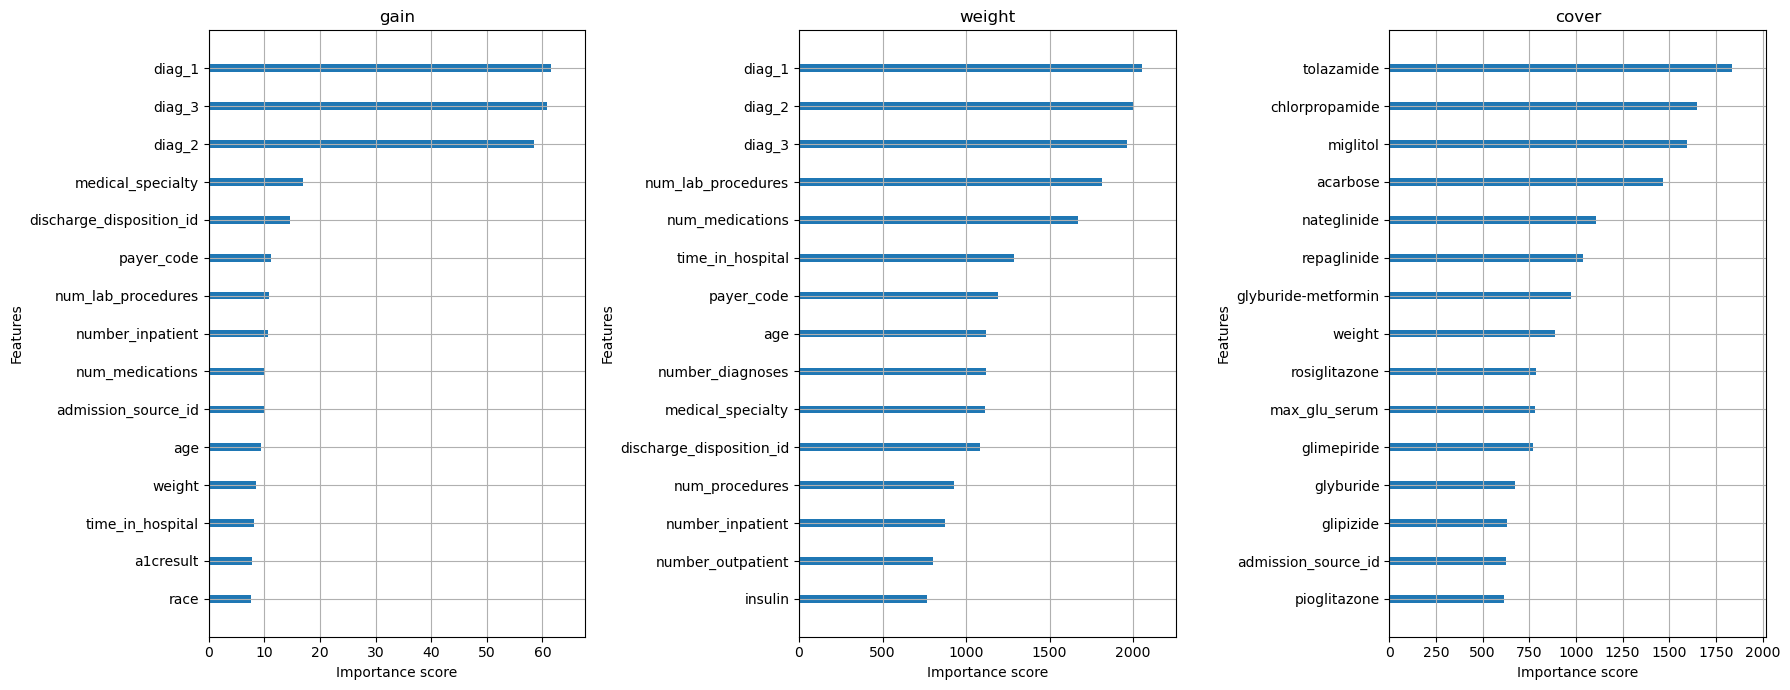

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, t in zip(axes, ["gain", "weight", "cover"]):
    xgb.plot_importance(model, importance_type=t, max_num_features=15, ax=ax, title=t, show_values=False)
plt.tight_layout()
plt.show()

# Logistic Regression Again

In [8]:
from sklearn.linear_model import LogisticRegression
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [9]:
num_cols = Xt.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = Xt.select_dtypes(include=['object','category']).columns.tolist()
features = num_cols+cat_cols

print(num_cols)
print(cat_cols)

['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'a1cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesmed']


In [10]:
# We use pipelines to make the feature selection and data cleaning process quicker

num = Pipeline([("imp", SimpleImputer(strategy="median")),("scale", StandardScaler())])
cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",min_frequency=20))])
prep = ColumnTransformer([("num", num, num_cols),("cat", cat, cat_cols)])
clf = Pipeline([("prep", prep), ("model", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.75, C=0.5, class_weight="balanced", max_iter=250, random_state=42))])

In [11]:
# Fit the model to the training data
clf.fit(Xt,yt)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

In [12]:
probs = clf.predict_proba(Xv)[:,1]
score(yv, y_pred=None, proba=probs, threshold=0.25)

Accuracy: 0.174
Confusion matrix:
 [[ 1043 13423]
 [   20  1797]]
              precision    recall  f1-score   support

           0       0.98      0.07      0.13     14466
           1       0.12      0.99      0.21      1817

    accuracy                           0.17     16283
   macro avg       0.55      0.53      0.17     16283
weighted avg       0.88      0.17      0.14     16283

F1 @0.5: 0.211
ROC-AUC: 0.667
PR-AUC:  0.2215
Best-threshold F1: 0.28110 at threshold 0.57142.


# CatBoost

We consider a catboost model.

In [13]:
from catboost import CatBoostClassifier
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [14]:
# prepare for catboost
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]


# careful!! catboost demands categorical columns to have string entry
Xt_cb, Xv_cb = Xt.copy(), Xv.copy()
for c in cat_cols:
    for df in (Xt_cb, Xv_cb):
        df[c] = df[c].astype(object).where(df[c].notna(), "missing").astype(str)


# fitting to the training set, we determine the scale positive weight
# it resolves the class imbalance 
spw = (yt == 0).sum() / (yt == 1).sum()

model = CatBoostClassifier(
    iterations=1_000, # choose a slightly high number of iterations due to no feature selection
    learning_rate=0.05,
    depth=5, 
    l2_leaf_reg=2, # l2 regularization to shift weights closer to 0
    scale_pos_weight=spw, # this handles class imbalance
    random_seed=42,
    verbose=50, # choose verbose to print every 100 iterations
    loss_function="Logloss",
    # task_type="GPU",
    # devices="0",
    eval_metric="Logloss:use_weights=false",
    allow_writing_files=False,
)
model.fit(Xt_cb, yt, cat_features=cat_cols)

0:	learn: 0.6904715	total: 151ms	remaining: 2m 30s
50:	learn: 0.6468779	total: 4.37s	remaining: 1m 21s
100:	learn: 0.6395629	total: 8.51s	remaining: 1m 15s
150:	learn: 0.6361334	total: 12.6s	remaining: 1m 10s
200:	learn: 0.6334842	total: 16.5s	remaining: 1m 5s
250:	learn: 0.6296647	total: 20.7s	remaining: 1m 1s
300:	learn: 0.6256517	total: 25.1s	remaining: 58.3s
350:	learn: 0.6222551	total: 30s	remaining: 55.5s
400:	learn: 0.6193030	total: 34.7s	remaining: 51.8s
450:	learn: 0.6161731	total: 39.1s	remaining: 47.6s
500:	learn: 0.6138271	total: 43.8s	remaining: 43.7s
550:	learn: 0.6115668	total: 48.3s	remaining: 39.3s
600:	learn: 0.6092061	total: 52.9s	remaining: 35.1s
650:	learn: 0.6070226	total: 57.6s	remaining: 30.9s
700:	learn: 0.6047689	total: 1m 2s	remaining: 26.6s
750:	learn: 0.6026870	total: 1m 7s	remaining: 22.2s
800:	learn: 0.6003283	total: 1m 11s	remaining: 17.8s
850:	learn: 0.5981754	total: 1m 16s	remaining: 13.3s
900:	learn: 0.5958063	total: 1m 20s	remaining: 8.86s
950:	learn

CatBoostClassifier(allow_writing_files=False, depth=5, eval_metric='Logloss:use_weights=false', iterations=1000, l2_leaf_reg=2, learning_rate=0.05, loss_function='Logloss', random_seed=42, scale_pos_weight=np.float64(7.9610621904237755), verbose=50)

In [15]:
proba = model.predict_proba(Xv_cb)[:, 1]
score(yv, y_pred=None, proba=proba, threshold=0.58)

Accuracy: 0.784
Confusion matrix:
 [[12021  2445]
 [ 1074   743]]
              precision    recall  f1-score   support

           0       0.92      0.83      0.87     14466
           1       0.23      0.41      0.30      1817

    accuracy                           0.78     16283
   macro avg       0.58      0.62      0.58     16283
weighted avg       0.84      0.78      0.81     16283

F1 @0.5: 0.297
ROC-AUC: 0.6862
PR-AUC:  0.2401
Best-threshold F1: 0.29858 at threshold 0.58651.


# LightGBM

In [16]:
import lightgbm as lgb 
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [17]:
# prepare for lgb
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]

Xt_lgb, Xv_lgb = Xt.copy(), Xv.copy()
for c in cat_cols:
    dtype = pd.CategoricalDtype(categories=Xt[c].dropna().astype(str).unique())
    Xt_lgb[c] = Xt[c].astype(str).astype(dtype)
    Xv_lgb[c] = Xv[c].astype(str).astype(dtype)


const = [c for c in Xt.columns if Xt[c].nunique(dropna=False) <= 1]

# near-constant: >99.5% one value
near_const = [c for c in Xt.columns
              if Xt[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.995]

model = lgb.LGBMClassifier(
    n_estimators= 1_000,
    learning_rate=0.05,
    num_leaves=35,
    min_child_samples=50,
    subsample=0.8, 
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=15,
    cat_smooth=65,          # regularizes rare category levels
    min_data_per_group=1_000, # ensure enough data per group is used 
    is_unbalance=True,   # do this instead of spw
    random_state=42,
    verbose=-1,
)
model.fit(Xt_lgb, yt)   # pandas 'category' columns are detected automatically

,boosting_type,'gbdt'
,num_leaves,35
,max_depth,-1
,learning_rate,0.05
,n_estimators,1000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,50


In [18]:
# Check feature importance
imp = pd.Series(model.booster_.feature_importance(importance_type="gain"),
                index=Xt_lgb.columns).sort_values(ascending=False)

print(f"Top Ten Most Important Features by Gain")
print(imp[0:10])

Top Ten Most Important Features by Gain
diag_1                      118007.790998
diag_3                       97627.963566
diag_2                       97135.397853
num_lab_procedures           84395.399544
num_medications              64837.888471
number_inpatient             51211.520001
discharge_disposition_id     42027.954714
time_in_hospital             40798.959877
age                          26636.560431
number_diagnoses             26501.909645
dtype: float64


In [19]:
proba = model.predict_proba(Xv_lgb)[:, 1]
score(yv, y_pred=None, proba=proba, threshold=0.58)

Accuracy: 0.827
Confusion matrix:
 [[12979  1487]
 [ 1323   494]]
              precision    recall  f1-score   support

           0       0.91      0.90      0.90     14466
           1       0.25      0.27      0.26      1817

    accuracy                           0.83     16283
   macro avg       0.58      0.58      0.58     16283
weighted avg       0.83      0.83      0.83     16283

F1 @0.5: 0.26
ROC-AUC: 0.6664
PR-AUC:  0.2147
Best-threshold F1: 0.27596 at threshold 0.44251.


# RandomForest Classifier

In [20]:
from sklearn.ensemble import RandomForestClassifier
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [21]:
num_cols = Xt.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = Xt.select_dtypes(include=['object','category']).columns.tolist()
features = num_cols+cat_cols

In [22]:
# We use pipelines to make the feature selection and data cleaning process quicker

num = Pipeline([("imp", SimpleImputer(strategy="median")),("scale", StandardScaler())])
cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",min_frequency=20))])
prep = ColumnTransformer([("num", num, num_cols),("cat", cat, cat_cols)])
clf = Pipeline([("prep", prep), ("model", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced'))])


In [23]:
# Fit the model to the training data
clf.fit(Xt,yt)

# Have the model now make predictions
labels = clf.predict(Xv)

In [24]:
probs = clf.predict_proba(Xv)[:,1]
score(yv, y_pred=None, proba=probs, threshold=0.58)

Accuracy: 0.888
Confusion matrix:
 [[14466     0]
 [ 1817     0]]
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     14466
           1       0.00      0.00      0.00      1817

    accuracy                           0.89     16283
   macro avg       0.44      0.50      0.47     16283
weighted avg       0.79      0.89      0.84     16283

F1 @0.5: 0.0
ROC-AUC: 0.6593
PR-AUC:  0.211
Best-threshold F1: 0.27289 at threshold 0.15000.


# Conclusions

So far, it seems like CatBoost is able to provide the best F1-Scores. It's $F_1$-score with probability $0.58$ is $0.2986$. This is marginally better than the $F_1$-score of $0.2773$ that our modeling baseline gets. Furthermore, here, the threshold is $0.58$ meanwhile the modeling baseline had to use threshold $0.1380$ for its best score.